# 01 Data Preparation: AI ล่าเที่ยวบินตัวร้าย 2% (Contrail)

Notebook นี้ทำขั้น 1–3 ของ flow chart
1. สร้างเส้นทางบินจำลองในยุโรป + ดึงข้อมูลอากาศ ERA5
2. รันโมเดลฟิสิกส์ CoCiP (pycontrails) เพื่อหาค่า EF ของแต่ละช่วงบิน
3. สร้าง label ตัวร้าย = กลุ่มช่วงบินที่รวมกันได้ 80% ของ EF ทั้งหมด (ตาม Teoh et al.)

**แหล่งข้อมูลอากาศ:** ค่าเริ่มต้นใช้ ARCO-ERA5 ที่ Google เปิดให้โหลดฟรีบน Google Cloud **ไม่ต้องสมัคร ไม่ต้องรอคิว** (ERA5 ชุดเดียวกับของ Copernicus) ถ้าอยากใช้ CDS ให้ตั้ง `DATA_SOURCE = "cds"

**ลำดับการรัน:** รอบแรกให้ `N_DAYS = 1` เพื่อทดสอบว่า pipeline ใช้ได้ แล้วค่อยเพิ่มเป็น 7–14 วัน

In [1]:
!pip -q install "pycontrails[ecmwf]" pyarrow gcsfs zarr h5netcdf h5py

## เชื่อม Drive (+ key ของ CDS ถ้าจะใช้ CDS)
ถ้าใช้ ARCO (ค่าเริ่มต้น) ข้ามขั้น key ได้เลย ถ้าใช้ CDS ทำตามนี้
1. สมัครฟรีที่ https://cds.climate.copernicus.eu แล้วล็อกอิน
2. เปิดหน้า dataset **ERA5 hourly data on pressure levels** และ **ERA5 hourly data on single levels** แล้วกดยอมรับ licence ที่แท็บ Download (ไม่ยอมรับจะโหลดไม่ได้)
3. ก๊อป Personal Access Token จากหน้าโปรไฟล์
4. ใน Colab กดไอคอนกุญแจ (Secrets) ด้านซ้าย เพิ่มชื่อ `CDSAPI_KEY` ใส่ token แล้วเปิดสิทธิ์ให้ notebook นี้

In [2]:
from google.colab import userdata, drive
import pathlib

try:
    key = userdata.get("CDSAPI_KEY")
    pathlib.Path("/root/.cdsapirc").write_text(f"url: https://cds.climate.copernicus.eu/api\nkey: {key}\n")
except Exception:
    print("ไม่มี CDSAPI_KEY ใช้ ARCO ได้ตามปกติ")

# เก็บผลลัพธ์ไว้ใน Google Drive จะได้ไม่หายเมื่อ Colab ตัดการเชื่อมต่อ
drive.mount("/content/drive")
OUT_DIR = pathlib.Path("/content/drive/MyDrive/Environmental-ML-Project/data")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("save to:", OUT_DIR)

# เก็บไฟล์ ERA5 ที่โหลดแล้วไว้ใน Drive ถ้า Colab หลุด รันใหม่จะไม่ต้องรอคิว CDS ซ้ำ
from pycontrails import DiskCacheStore
CACHE = DiskCacheStore(cache_dir=str(OUT_DIR.parent / "era5_cache"))

Mounted at /content/drive
save to: /content/drive/MyDrive/Environmental-ML-Project/data


## ตั้งค่าการทดลอง
- เดือนมกราคม 2024 (หน้าหนาว contrail เกิดบ่อย ตามงานของ Stuber)
- ระดับความกดอากาศ 150–400 hPa ครอบคลุมเพดานบิน FL300–FL400
- ARCO ได้ความละเอียด 0.25° ตัดเฉพาะพื้นที่ที่ศึกษา ส่วน CDS ใช้ `GRID = 1.0` องศาเพื่อให้ไฟล์เล็ก

In [12]:
import numpy as np
import pandas as pd

SEED = 42
rng = np.random.default_rng(SEED)

REGION = "europe"          # "europe" หรือ "sea" (ไทย/อาเซียน)
START_DAY = pd.Timestamp("2024-01-08") if REGION == "europe" else pd.Timestamp("2024-08-05")  # อาเซียนใช้ฤดูฝน อากาศชั้นบนชื้นกว่า
N_DAYS = 7                 # รอบแรก 1 วันเพื่อทดสอบ แล้วค่อยเพิ่ม
FLIGHTS_PER_DAY = 150
PRESSURE_LEVELS = [400, 350, 300, 250, 225, 200, 175, 150]
GRID = 1.0                 # ใช้กับ CDS เท่านั้น
DATA_SOURCE = "arco"       # "arco" (ไม่ต้องรอคิว) หรือ "cds"
BBOX = {"europe": ((-95, 40), (30, 70)), "sea": ((85, 130), (-15, 30))}[REGION]  # (ลองจิจูด), (ละติจูด)
CRUISE_FL = [300, 320, 340, 360, 380, 400]
NARROWBODY = ["A320", "A321", "B738", "A20N"]   # เครื่องลำตัวแคบ บินระยะสั้น-กลาง
WIDEBODY = ["A359", "B77W", "B789", "A333"]     # A350, 777-300ER, 787-9, A330 บินข้ามทวีป
STRIDE = 2                 # ARCO 0.25° → ใช้ทุก 2 จุด = 0.5° ประหยัดแรม 4 เท่า (Colab ฟรีมีแรม ~12 GB)
MET_HOURS = 40             # ข้อมูลอากาศต่อวัน: 24 ชม. + เผื่อไฟลต์ยาวที่ออกดึกและ contrail ที่อยู่ต่อ
CRUISE_SPEED_MS = 230.0    # ~ Mach 0.78
STEP_S = 60                # 1 จุดต่อนาที
MIN_DISTANCE_KM = 500

## ขั้น 1a: สร้างเส้นทางบินจำลอง
บินตามเส้นทางที่สั้นที่สุดบนผิวโลก (great circle) ที่ความสูงคงที่ ไม่จำลองช่วงไต่และลด (contrail ส่วนใหญ่เกิดที่เพดานบินอยู่แล้ว)

- ยุโรปรวมเส้นทาง**ข้ามแอตแลนติกเหนือ** (ยุโรป ↔ อเมริกาเหนือ) ซึ่งเป็นย่านที่ contrail หนาแน่นที่สุดแห่งหนึ่งของโลก
- เลือกรุ่นเครื่องตามระยะทางแบบสายการบินจริง: เกิน 3,000 กม. ใช้ลำตัวกว้าง (A350, 777, 787, A330), 1,500–3,000 กม. สุ่มทั้งสองแบบ, ต่ำกว่านั้นใช้ลำตัวแคบ
- เครื่องใหญ่เผาน้ำมันมากกว่า ปล่อยไอน้ำกับเขม่ามากกว่า แต่เครื่องยนต์รุ่นใหม่อย่างของ A350/787 ปล่อยเขม่าน้อยกว่า ซึ่งมีผลต่อจำนวนผลึกน้ำแข็งใน contrail จึงเป็นคำถามที่ให้ SHAP ตอบได้ว่ารุ่นเครื่องสำคัญแค่ไหน

In [13]:
AIRPORTS_EUROPE = {
    "LHR": (51.47, -0.45), "CDG": (49.01, 2.55), "AMS": (52.31, 4.76), "FRA": (50.03, 8.57),
    "MAD": (40.47, -3.56), "BCN": (41.30, 2.08), "FCO": (41.80, 12.25), "MUC": (48.35, 11.79),
    "IST": (41.26, 28.74), "ZRH": (47.46, 8.55), "VIE": (48.11, 16.57), "CPH": (55.62, 12.65),
    "OSL": (60.19, 11.10), "ARN": (59.65, 17.92), "HEL": (60.32, 24.96), "DUB": (53.42, -6.27),
    "LIS": (38.77, -9.13), "ATH": (37.94, 23.94), "WAW": (52.17, 20.97), "PRG": (50.10, 14.26),
    "BRU": (50.90, 4.48), "MXP": (45.63, 8.72),
    # อเมริกาเหนือ สำหรับเส้นทางข้ามแอตแลนติก
    "JFK": (40.64, -73.78), "BOS": (42.36, -71.01), "IAD": (38.95, -77.46), "YYZ": (43.68, -79.63),
    "ORD": (41.98, -87.90), "YUL": (45.47, -73.74),
}
AIRPORTS_SEA = {
    "BKK": (13.69, 100.75), "CNX": (18.77, 98.96), "HKT": (8.11, 98.32), "SIN": (1.36, 103.99),
    "KUL": (2.74, 101.70), "HAN": (21.22, 105.81), "SGN": (10.82, 106.66), "HKG": (22.31, 113.91),
    "MNL": (14.51, 121.02), "CGK": (-6.13, 106.66), "RGN": (16.91, 96.13), "PNH": (11.55, 104.84),
    "VTE": (17.99, 102.56), "DPS": (-8.75, 115.17),
}
AIRPORTS = AIRPORTS_EUROPE if REGION == "europe" else AIRPORTS_SEA
R_EARTH_KM = 6371.0

def to_xyz(lat, lon):
    lat, lon = np.radians(lat), np.radians(lon)
    return np.array([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)])

def great_circle(lat1, lon1, lat2, lon2, n):
    a, b = to_xyz(lat1, lon1), to_xyz(lat2, lon2)
    omega = np.arccos(np.clip(a @ b, -1, 1))
    t = np.linspace(0, 1, n)[:, None]
    p = (np.sin((1 - t) * omega) * a + np.sin(t * omega) * b) / np.sin(omega)
    lat = np.degrees(np.arcsin(p[:, 2]))
    lon = np.degrees(np.arctan2(p[:, 1], p[:, 0]))
    return lat, lon, omega * R_EARTH_KM

ROUTES = []
codes = list(AIRPORTS)
for i, o in enumerate(codes):
    for d in codes[i + 1:]:
        _, _, dist = great_circle(*AIRPORTS[o], *AIRPORTS[d], 2)
        if dist >= MIN_DISTANCE_KM:
            ROUTES += [(o, d, dist), (d, o, dist)]
print(len(ROUTES), "routes")

700 routes


In [14]:
from pycontrails import Flight

def make_flights(day, n):
    flights = []
    for k in range(n):
        o, d, dist = ROUTES[rng.integers(len(ROUTES))]
        dep = day + pd.Timedelta(minutes=int(rng.integers(0, 24 * 60)))
        n_pts = max(int(dist * 1000 / CRUISE_SPEED_MS / STEP_S), 2)
        lat, lon, _ = great_circle(*AIRPORTS[o], *AIRPORTS[d], n_pts)
        fl = int(rng.choice(CRUISE_FL))
        df = pd.DataFrame({
            "longitude": lon,
            "latitude": lat,
            "altitude_ft": float(fl * 100),
            "time": dep + pd.to_timedelta(np.arange(n_pts) * STEP_S, unit="s"),
        })
        flight_id = f"{day:%Y%m%d}-{k:04d}-{o}{d}"
        pool = WIDEBODY if dist > 3000 else (NARROWBODY + WIDEBODY if dist > 1500 else NARROWBODY)
        attrs = {"flight_id": flight_id, "aircraft_type": str(rng.choice(pool)),
                 "origin": o, "destination": d, "flight_level": fl}
        flights.append(Flight(df, attrs=attrs))
    return flights

test = make_flights(START_DAY, 3)
test[0].dataframe.head()

,longitude,latitude,altitude_ft,time
0,2.550000,49.010000,36000.0,2024-01-08 18:34:00
1,2.657617,49.114239,36000.0,2024-01-08 18:35:00
2,2.765687,49.218378,36000.0,2024-01-08 18:36:00
3,2.874214,49.322416,36000.0,2024-01-08 18:37:00
4,2.983199,49.426351,36000.0,2024-01-08 18:38:00


## ขั้น 1b + 2: ดึง ERA5 และรัน CoCiP ทีละวัน
- ดึงอากาศของวันนั้นต่อไปอีก 40 ชม. เพราะไฟลต์ข้ามทวีปที่ออกดึกยังบินอยู่วันถัดไป และ contrail อยู่ต่อได้อีกหลายชั่วโมง
- ARCO ใช้เวลาโหลดราว 2–5 นาทีต่อวันใน Colab (โหลดครั้งเดียว แล้วเก็บไว้ใน Drive) ส่วน CDS ต้องรอคิว
- บันทึกผลเป็นไฟล์รายวันใน Drive ถ้า Colab หลุด รันต่อได้จากวันที่ยังไม่มีไฟล์

In [15]:
from pycontrails.datalib.ecmwf import ERA5
from pycontrails.models.cocip import Cocip
from pycontrails.models.humidity_scaling import ExponentialBoostLatitudeCorrectionHumidityScaling
from pycontrails.models.ps_model import PSFlight

# คอลัมน์ที่เก็บไว้เป็น feature (ไม่เก็บผลภายในของ CoCiP เช่น sac/persistent เพราะจะรั่วคำตอบ)
FEATURE_COLS = ["air_temperature", "specific_humidity", "rh", "rhi", "u_wind", "v_wind",
                "air_pressure", "fuel_flow", "true_airspeed", "thrust_setting", "engine_efficiency"]

import gc
from concurrent.futures import ThreadPoolExecutor
import xarray as xr
from pycontrails import MetDataset

ARCO_URL = "gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3"
ARCO_PL = {"temperature": "air_temperature", "specific_humidity": "specific_humidity",
           "u_component_of_wind": "eastward_wind", "v_component_of_wind": "northward_wind",
           "vertical_velocity": "lagrangian_tendency_of_air_pressure", "geopotential": "geopotential",
           "specific_cloud_ice_water_content": "specific_cloud_ice_water_content"}
ARCO_RAD = ["top_net_solar_radiation", "top_net_thermal_radiation"]
_arco = None

def _crop(ds):
    (lon0, lon1), (lat0, lat1) = BBOX
    ds = ds.sel(latitude=slice(lat1, lat0))                      # ARCO เรียงละติจูดจากเหนือลงใต้
    ds = ds.assign_coords(longitude=((ds.longitude + 180) % 360) - 180).sortby("longitude")
    ds = ds.sel(longitude=slice(lon0, lon1)).sortby("latitude")
    return ds.isel(latitude=slice(None, None, STRIDE), longitude=slice(None, None, STRIDE))

def _load_small(var, t, levels=None):
    # โหลดทีละตัวแปร ทีละชั่วโมง ไม่ขนาน: ARCO เก็บข้อมูลทั้งโลกเป็นก้อนละชั่วโมง (~150 MB)
    # ถ้าโหลดหลายก้อนพร้อมกัน แรม Colab ฟรีจะเต็มจน crash วิธีนี้ช้ากว่าแต่ใช้แรมแค่ราว 1 ก้อน
    # ใช้ตำแหน่ง (isel) แทนการค้นด้วยค่า (sel): ใน Colab แกนเวลาของ ARCO อ่านออกมามีค่าซ้ำ ทำให้ .sel พัง
    tvals = _arco["time"].values
    lvals = _arco["level"].values
    parts = []
    for ti in t:
        hit = np.flatnonzero(tvals == np.datetime64(ti, "ns"))
        if len(hit) == 0:
            raise KeyError(f"ไม่มีข้อมูลเวลา {ti} ใน ARCO")
        da = _arco[var].isel(time=[int(hit[0])])
        if levels is not None:
            da = da.isel(level=[int(np.flatnonzero(lvals == lv)[0]) for lv in levels])
        parts.append(_crop(da).load())
    return xr.concat(parts, dim="time")

def load_met_arco(day):
    global _arco
    cache = OUT_DIR.parent / "era5_arco" / f"{REGION}_{day:%Y%m%d}"
    if not (cache / "pl.nc").exists():
        if _arco is None:
            _arco = xr.open_zarr(ARCO_URL, chunks=None, storage_options={"token": "anon"})  # ไม่ใช้ dask
        t = pd.date_range(day, day + pd.Timedelta(hours=MET_HOURS), freq="h")
        # โหลด 3 ตัวแปรพร้อมกัน (แรมรวมราว 2–3 GB ยังห่างจากเพดาน Colab)
        with ThreadPoolExecutor(max_workers=3) as ex:
            pl_parts = dict(zip(ARCO_PL.values(), ex.map(lambda v: _load_small(v, t, PRESSURE_LEVELS), ARCO_PL)))
            rad_parts = dict(zip(ARCO_RAD, ex.map(lambda v: _load_small(v, t), ARCO_RAD)))
        pl = xr.Dataset(pl_parts)
        rad = xr.Dataset(rad_parts).expand_dims(level=[-1.0])
        print(f"  โหลด ERA5 {day.date()} เสร็จ")
        cache.mkdir(parents=True, exist_ok=True)
        pl.to_netcdf(cache / "pl.nc", engine="h5netcdf", encoding={v: {"zlib": True} for v in pl.data_vars})
        rad.to_netcdf(cache / "rad.nc", engine="h5netcdf", encoding={v: {"zlib": True} for v in rad.data_vars})
    pl = xr.load_dataset(cache / "pl.nc", engine="h5netcdf")
    rad = xr.load_dataset(cache / "rad.nc", engine="h5netcdf")
    for ds in (pl, rad):
        ds.attrs.update(provider="ECMWF", dataset="ERA5", product="reanalysis")
    for v in ARCO_RAD:
        rad[v].attrs["units"] = "J m**-2"   # ค่าสะสมรายชั่วโมง แบบเดียวกับ ERA5 ของ CDS
    return MetDataset(pl), MetDataset(rad)

def load_met(day):
    if DATA_SOURCE == "arco":
        return load_met_arco(day)
    time = (day, day + pd.Timedelta(hours=MET_HOURS))
    pl = ERA5(time=time, variables=Cocip.met_variables + Cocip.optional_met_variables,
              pressure_levels=PRESSURE_LEVELS, grid=GRID, cachestore=CACHE)
    sl = ERA5(time=time, variables=Cocip.rad_variables, grid=GRID, cachestore=CACHE)
    return pl.open_metdataset(), sl.open_metdataset()

def run_day(day):
    out_path = OUT_DIR / f"cocip_{REGION}_{day:%Y%m%d}.parquet"
    if out_path.exists():
        print("skip", day.date())
        return pd.read_parquet(out_path)

    met, rad = load_met(day)
    flights = make_flights(day, FLIGHTS_PER_DAY)
    cocip = Cocip(met=met, rad=rad,
                  humidity_scaling=ExponentialBoostLatitudeCorrectionHumidityScaling(),
                  aircraft_performance=PSFlight())
    result = cocip.eval(source=flights)

    # ดึงเฉพาะคอลัมน์ที่ใช้จากแต่ละเที่ยวบิน (ผลของ CoCiP บางเที่ยวมีชื่อคอลัมน์ซ้ำ ทำให้ pd.concat พังใน Colab)
    base_cols = ["time", "longitude", "latitude", "altitude_ft", "ef"] + FEATURE_COLS
    rows = []
    for fl in result:
        src = fl.dataframe
        src = src.loc[:, ~src.columns.duplicated()]
        part = pd.DataFrame({c: src[c].to_numpy() for c in base_cols if c in src})
        for k in ["flight_id", "aircraft_type", "origin", "destination", "flight_level"]:
            part[k] = fl.attrs[k]
        rows.append(part)
    df = pd.concat(rows, ignore_index=True)
    df["ef"] = df["ef"].fillna(0.0) if "ef" in df else 0.0
    keep = ["flight_id", "time", "longitude", "latitude", "altitude_ft", "flight_level",
            "aircraft_type", "origin", "destination", "ef"] + [c for c in FEATURE_COLS if c in df]
    df = df[keep]
    df.to_parquet(out_path)
    print(day.date(), len(df), "segments,", (df["ef"] != 0).mean().round(3), "with contrail EF")
    del met, rad, cocip, result, rows   # คืนแรมก่อนขึ้นวันถัดไป
    gc.collect()
    return df

## (เฉพาะ CDS) โหลด ERA5 ล่วงหน้าแบบขนาน
ถ้าใช้ ARCO ข้าม cell นี้ได้เลย

CDS รับคำขอ **ทีละวันปฏิทิน** และแต่ละคำขอต้องเข้าคิว (ปกติ 2–30 นาที ช่วงคนใช้เยอะอาจเป็นชั่วโมง) cell นี้ส่งคำขอทุกวันพร้อมกัน 4 คำขอ แทนที่จะรอทีละอัน
- ถ้าเห็นสถานะ `accepted` แปลว่ายังรอคิวอยู่ ไม่ได้ค้าง ดูคิวได้ที่ https://cds.climate.copernicus.eu/requests
- ไฟล์ถูกเก็บใน Drive ถ้าหลุดกลางทาง รัน cell นี้ใหม่จะโหลดเฉพาะวันที่ยังขาด

In [7]:
from concurrent.futures import ThreadPoolExecutor, as_completed

def fetch(kind, d):
    t = (d, d + pd.Timedelta(hours=23))
    if kind == "pressure":
        src = ERA5(time=t, variables=Cocip.met_variables + Cocip.optional_met_variables,
                   pressure_levels=PRESSURE_LEVELS, grid=GRID, cachestore=CACHE)
    else:
        src = ERA5(time=t, variables=Cocip.rad_variables, grid=GRID, cachestore=CACHE)
    src.download()
    return kind, d.date()

if DATA_SOURCE != "cds":
    raise SystemExit("ใช้ ARCO อยู่ ไม่ต้องรัน cell นี้")
need = pd.date_range(START_DAY, periods=N_DAYS + 2, freq="D")  # +วันถัดไปเพราะ contrail อยู่ข้ามคืน
jobs = [(k, d) for d in need for k in ["pressure", "single"]]
with ThreadPoolExecutor(max_workers=4) as ex:
    for f in as_completed([ex.submit(fetch, k, d) for k, d in jobs]):
        print("done", *f.result())

SystemExit: ใช้ ARCO อยู่ ไม่ต้องรัน cell นี้

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [16]:
# รันทีละวัน วันที่เสร็จแล้วจะถูกข้าม ถ้า Colab หลุดกลางทาง กด Run cell นี้ใหม่ได้เลย
days = pd.date_range(START_DAY, periods=N_DAYS, freq="D")
for d in days:
    run_day(d)
data = pd.concat([pd.read_parquet(OUT_DIR / f"cocip_{REGION}_{d:%Y%m%d}.parquet") for d in days], ignore_index=True)
print(data.shape)
data.describe().T

skip 2024-01-08
  โหลด ERA5 2024-01-09 เสร็จ


/usr/local/lib/python3.13/dist-packages/pycontrails/models/cocip/cocip.py:2580: UserWarning: At time 2024-01-10T16:00:00.000000, the contrail has no intersection with the met data. This is likely due to the contrail being advected outside the met domain.
  warnings.warn(


2024-01-09 36137 segments, 0.141 with contrail EF
  โหลด ERA5 2024-01-10 เสร็จ


/usr/local/lib/python3.13/dist-packages/pycontrails/models/cocip/cocip.py:2580: UserWarning: At time 2024-01-11T16:30:00.000000, the contrail has no intersection with the met data. This is likely due to the contrail being advected outside the met domain.
  warnings.warn(


2024-01-10 38144 segments, 0.141 with contrail EF
  โหลด ERA5 2024-01-11 เสร็จ


/usr/local/lib/python3.13/dist-packages/pycontrails/models/cocip/cocip.py:2580: UserWarning: At time 2024-01-12T16:30:00.000000, the contrail has no intersection with the met data. This is likely due to the contrail being advected outside the met domain.
  warnings.warn(


... (4 outputs left out)

2024-01-13 38194 segments, 0.172 with contrail EF
  โหลด ERA5 2024-01-14 เสร็จ


/usr/local/lib/python3.13/dist-packages/pycontrails/models/cocip/cocip.py:2580: UserWarning: At time 2024-01-15T16:30:00.000000, the contrail has no intersection with the met data. This is likely due to the contrail being advected outside the met domain.
  warnings.warn(


2024-01-14 35500 segments, 0.153 with contrail EF
(263045, 21)


,count,mean,min,25%,50%,75%,max,std
time,263045,2024-01-11 15:40:45.794293504,2024-01-08 00:20:00,2024-01-09 22:34:00,2024-01-11 18:40:00,2024-01-13 08:09:00,2024-01-15 07:49:00,NaN
longitude,263045.0,-25.168194,-87.9,-53.629994,-22.402422,2.835051,28.74,31.159771
latitude,263045.0,50.500151,37.94,46.229008,50.759424,54.223205,67.832289,5.705884
altitude_ft,263045.0,34916.193047,30000.0,32000.0,34000.0,38000.0,40000.0,3384.526103
flight_level,263045.0,349.16193,300.0,320.0,340.0,380.0,400.0,33.845261
ef,263045.0,715241389723.090454,-49753770565050.75,0.0,0.0,0.0,199705320982703.9375,5160137673047.098633
air_temperature,263045.0,217.839813,198.539551,213.558914,218.350876,222.338394,234.305359,5.985324
specific_humidity,263045.0,0.000024,0.000002,0.000007,0.000013,0.000027,0.000326,0.00003
rh,263045.0,0.276244,0.007541,0.0826,0.215522,0.431042,0.950777,0.223156
rhi,263045.0,0.464557,0.011419,0.136636,0.363959,0.733073,1.581605,0.374799


## ขั้น 3: สร้าง label ตัวร้าย
เรียงช่วงบินจาก EF (ผลทำให้ร้อน) มากไปน้อย แล้วติดป้าย 1 ให้กลุ่มบนสุดที่รวมกันได้ 80% ของ EF บวกทั้งหมด (ตามนิยามของ Teoh et al.)

In [17]:
pos = data["ef"].clip(lower=0)
order = pos.sort_values(ascending=False)
cum_share = order.cumsum() / order.sum()
villain_idx = cum_share[cum_share <= 0.80].index
data["villain"] = 0
data.loc[villain_idx, "villain"] = 1

print(f"ช่วงบินทั้งหมด: {len(data):,}")
print(f"ตัวร้าย: {data['villain'].sum():,} ช่วง = {data['villain'].mean():.2%} ของช่วงบิน")
print(f"เที่ยวบินที่มีตัวร้ายอย่างน้อย 1 ช่วง: {data.groupby('flight_id')['villain'].max().mean():.2%}")

ช่วงบินทั้งหมด: 263,045
ตัวร้าย: 5,594 ช่วง = 2.13% ของช่วงบิน
เที่ยวบินที่มีตัวร้ายอย่างน้อย 1 ช่วง: 27.81%


## เพิ่ม feature พื้นฐาน (ใช้ต่อใน notebook 02)
- ชั่วโมงท้องถิ่นจากลองจิจูด และแปลงเป็น sin/cos เพราะ 23:00 กับ 00:00 อยู่ติดกัน (seasonality รายวัน, L11)
- กลางวัน/กลางคืนแบบหยาบจากชั่วโมงท้องถิ่น

In [18]:
t = pd.to_datetime(data["time"])
local_hour = (t.dt.hour + t.dt.minute / 60 + data["longitude"] / 15) % 24
data["local_hour"] = local_hour
data["hour_sin"] = np.sin(2 * np.pi * local_hour / 24)
data["hour_cos"] = np.cos(2 * np.pi * local_hour / 24)
night = (7, 17) if REGION == "europe" else (6.5, 18.5)  # มกราคมในยุโรปมืดเร็ว ไทยกลางวันยาวกว่า
data["is_night"] = ((local_hour < night[0]) | (local_hour >= night[1])).astype(int)
data["region"] = REGION

data.to_parquet(OUT_DIR / f"dataset_{REGION}_v1.parquet")
print("saved", OUT_DIR / f"dataset_{REGION}_v1.parquet", data.shape)
data.head()

saved /content/drive/MyDrive/Environmental-ML-Project/data/dataset_europe_v1.parquet (263045, 27)


,flight_id,time,longitude,latitude,altitude_ft,flight_level,aircraft_type,origin,destination,ef,...,fuel_flow,true_airspeed,thrust_setting,engine_efficiency,villain,local_hour,hour_sin,hour_cos,is_night,region
0,20240108-0000-BOSARN,2024-01-08 18:16:00,-71.010000,42.360000,38000.0,380,A333,BOS,ARN,0.0,...,1.489691,218.079557,0.470307,0.322555,0,13.532667,-0.390570,-0.920573,0,europe
1,20240108-0000-BOSARN,2024-01-08 18:17:00,-70.904473,42.457242,38000.0,380,A333,BOS,ARN,0.0,...,1.491844,218.548744,0.474073,0.322801,0,13.556368,-0.396275,-0.918132,0,europe
2,20240108-0000-BOSARN,2024-01-08 18:18:00,-70.798618,42.554388,38000.0,380,A333,BOS,ARN,0.0,...,1.490961,219.033008,0.476657,0.323160,0,13.580092,-0.401970,-0.915653,0,europe
3,20240108-0000-BOSARN,2024-01-08 18:19:00,-70.692433,42.651435,38000.0,380,A333,BOS,ARN,0.0,...,1.492405,219.482371,0.479626,0.323433,0,13.603838,-0.407654,-0.913136,0,europe
4,20240108-0000-BOSARN,2024-01-08 18:20:00,-70.585916,42.748385,38000.0,380,A333,BOS,ARN,0.0,...,1.492806,219.938684,0.482033,0.323754,0,13.627606,-0.413328,-0.910582,0,europe


## เช็กความสมเหตุสมผล
ถ้าทุกอย่างถูก ควรเห็นว่าตัวร้ายมีแค่ไม่กี่เปอร์เซ็นต์ และกระจุกในจุดที่อากาศชื้น (rhi สูง)

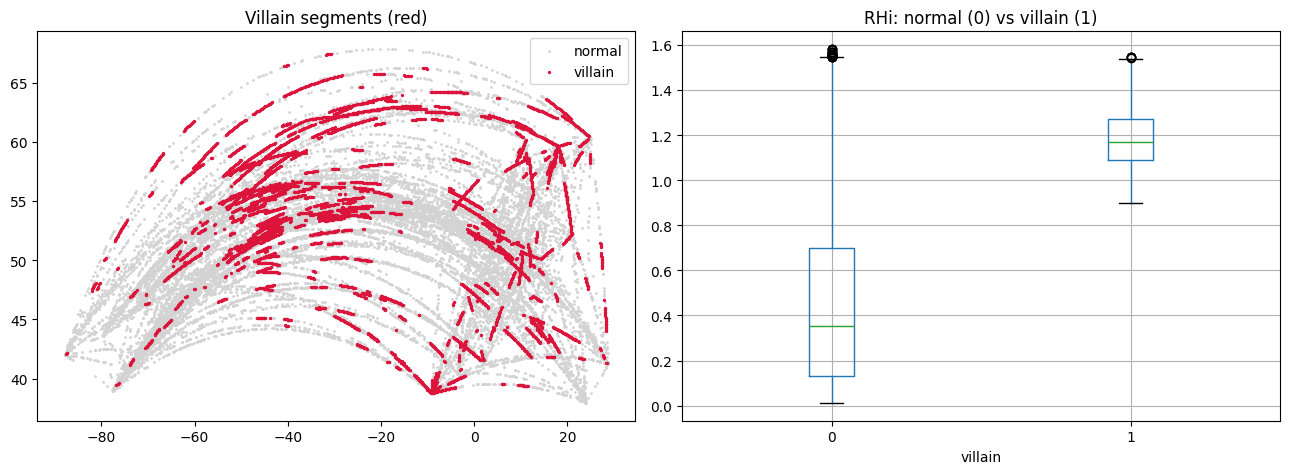

In [19]:
import matplotlib.pyplot as plt  # ป้ายกราฟเป็นอังกฤษ เพราะ Colab ไม่มีฟอนต์ไทย

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ok = data[data["villain"] == 0].sample(min(20000, (data["villain"] == 0).sum()), random_state=SEED)
bad = data[data["villain"] == 1]
ax[0].scatter(ok["longitude"], ok["latitude"], s=1, c="lightgray", label="normal")
ax[0].scatter(bad["longitude"], bad["latitude"], s=2, c="crimson", label="villain")
ax[0].set_title("Villain segments (red)"); ax[0].legend()
if "rhi" in data:
    data.boxplot(column="rhi", by="villain", ax=ax[1])
    ax[1].set_title("RHi: normal (0) vs villain (1)"); fig.suptitle("")
plt.tight_layout()
plt.show()